In [ ]:
---
execute:
  eval: false
  echo: true
  warning: false
format:
  html:
    code-fold: false
---

Importing the packages.

In [ ]:
#| echo: true
import torch
import matplotlib.pyplot as plt
from diffusers import (
    UNet2DModel,
    DDIMScheduler,
    EulerDiscreteScheduler,
    HeunDiscreteScheduler,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Loading a pre-trained model.

In [ ]:
#| echo: true
model_id = "1aurent/ddpm-mnist"
model = UNet2DModel.from_pretrained(model_id).to(device)
model.eval()

Creating helper functions.

In [4]:
#| echo: true
def plot_samples(samples, title, num_images=8):
    samples = (samples.clamp(-1, 1) + 1) / 2
    samples = samples.cpu().permute(0, 2, 3, 1).numpy()

    fig, axes = plt.subplots(1, num_images, figsize=(num_images * 1.8, 2))
    fig.suptitle(title, fontsize=14, y=1.05)
    for i in range(num_images):
        axes[i].imshow(samples[i, :, :, 0], cmap="gray")
        axes[i].axis("off")
    plt.tight_layout()
    plt.show()

@torch.no_grad()
def generate_with_scheduler(model, scheduler, num_steps=50, num_samples=8, step_kwargs=None):
    if step_kwargs is None:
        step_kwargs = {}

    scheduler.set_timesteps(num_steps)

    shape = (num_samples, 1, 28, 28)
    x = torch.randn(shape, device=device)

    if hasattr(scheduler, "init_noise_sigma"):
        x = x * scheduler.init_noise_sigma

    for t in scheduler.timesteps:
        model_input = scheduler.scale_model_input(x, t)
        noise_pred = model(model_input, t).sample
        x = scheduler.step(noise_pred, t, x, **step_kwargs).prev_sample

    return x

Using ODE samplers to generate samples using $50$ steps.

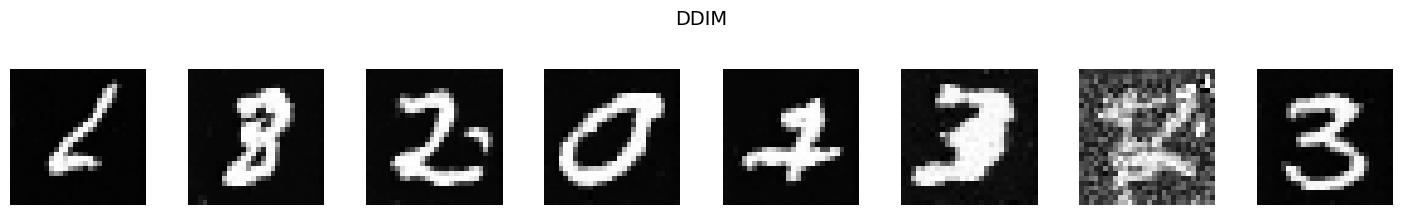

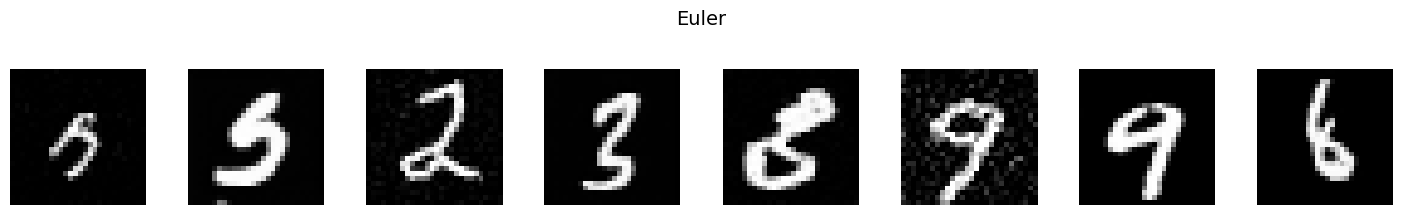

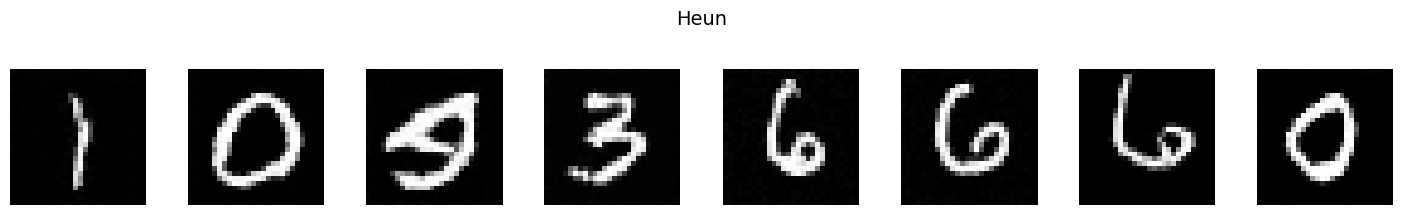

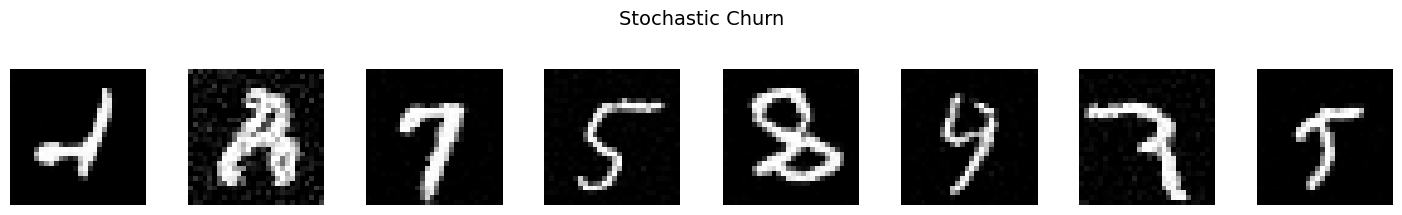

In [6]:
#| echo: true
ddim_scheduler = DDIMScheduler.from_pretrained(model_id)
samples_ddim = generate_with_scheduler(model, ddim_scheduler, num_steps=50, step_kwargs={"eta": 0.0})
plot_samples(samples_ddim, "DDIM")

euler_scheduler = EulerDiscreteScheduler.from_pretrained(model_id)
samples_euler = generate_with_scheduler(model, euler_scheduler, num_steps=50)
plot_samples(samples_euler, "Euler")

heun_scheduler = HeunDiscreteScheduler.from_pretrained(model_id)
samples_heun = generate_with_scheduler(model, heun_scheduler, num_steps=50)
plot_samples(samples_heun, "Heun")

churn_scheduler = EulerDiscreteScheduler.from_pretrained(model_id)
samples_churn = generate_with_scheduler(
    model,
    churn_scheduler,
    num_steps=50,
    step_kwargs={"s_churn": 0.2, "s_tmin": 0.0, "s_tmax": float("inf"), "s_noise": 1.0}
)

plot_samples(samples_churn, "Stochastic Churn")